In [4]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [5]:
import numpy as np

# 1. Corpus
corpus = ["cats like milk",
          "dogs like balls",
          "cats drink milk",
          "dogs chase cats"]

In [6]:
# 2. Build vocabulary
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)
print("Vocabulary:", vocab)

# Hyperparameters
window = 1
d = 3
learning_rate = 0.05
epochs = 500


Vocabulary: ['balls', 'cats', 'chase', 'dogs', 'drink', 'like', 'milk']


In [7]:
# 3. Generate center-context training pairs
pairs = []

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):
        for j in range(max(0, i - window),
                       min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Training pairs:", pairs)

Training pairs: [(1, 5), (5, 1), (5, 6), (6, 5), (3, 5), (5, 3), (5, 0), (0, 5), (1, 4), (4, 1), (4, 6), (6, 4), (3, 2), (2, 3), (2, 1), (1, 2)]


In [8]:
# 4. Initialize E (input embeddings) and W (output weights)
np.random.seed(0)
E = np.random.randn(V, d) * 0.1    # (V, d): embedding lookup table
W = np.random.randn(d, V) * 0.1    # (d, V): output weights


In [9]:
# 5. Helper: softmax
def softmax(x):
    e = np.exp(x - np.max(x))
    return e / e.sum()

In [10]:
# 6. Training loop
for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0

    for center, context in pairs:
        # Forward pass
        h = E[center]                      # embedding lookup
        scores = h @ W                     # (V,)
        probs = softmax(scores)            # (V,)

        # Loss
        loss = -np.log(probs[context])
        total_loss += loss

        # Backpropagation
        error = probs.copy()
        error[context] -= 1                # probs - one_hot(context)

        grad_W = np.outer(h, error)        # (d, V)
        grad_h = W @ error                 # (d,)  uses old W

        # Update parameters
        W -= learning_rate * grad_W
        E[center] -= learning_rate * grad_h

    if epoch % 100 == 0:
        print(f"epoch {epoch}, loss {total_loss / len(pairs):.4f}")

epoch 0, loss 1.9474
epoch 100, loss 1.0161
epoch 200, loss 1.0006
epoch 300, loss 0.9966
epoch 400, loss 0.9930


In [11]:
# 7. Return E: the learned word vectors
print("\nLearned embeddings:")
for i in range(V):
    print(f"{id_to_word[i]:>6}: {np.round(E[i], 3)}")


Learned embeddings:
 balls: [ 1.456 -2.481 -0.654]
  cats: [-0.985 -0.971 -0.173]
 chase: [2.147 0.447 0.804]
  dogs: [ 0.078 -1.766  1.096]
 drink: [-0.454  1.416  1.814]
  like: [ 0.306  1.184 -0.244]
  milk: [-0.021 -1.136 -1.765]


In [12]:
# 8. Check the result: most similar words (cosine similarity)
def most_similar(word, top_k=3):
    v = E[word_to_id[word]]
    sims = E @ v / (np.linalg.norm(E, axis=1) * np.linalg.norm(v))
    best = np.argsort(sims)[::-1][1:top_k + 1]   # skip the word itself
    return [(id_to_word[i], round(float(sims[i]), 3)) for i in best]

print("\nSimilar to 'cats':", most_similar("cats"))
print("Similar to 'dogs':", most_similar("dogs"))


Similar to 'cats': [('dogs', 0.499), ('milk', 0.488), ('balls', 0.264)]
Similar to 'dogs': [('balls', 0.616), ('cats', 0.499), ('chase', 0.053)]


In [13]:
# ---- check 1: shortcut loss == full cross-entropy formula ----
center, context = pairs[0]
h = E[center]
probs = softmax(h @ W)

y = np.zeros(V)
y[context] = 1                                  # one-hot target

loss_shortcut = -np.log(probs[context])         # what the training loop uses
loss_full = -np.sum(y * np.log(probs))          # -sum(y_k * log(p_k))
print(loss_shortcut, loss_full, np.isclose(loss_shortcut, loss_full))   # True

# ---- check 2: gradient (probs - y) matches a numerical gradient ----
def loss_fn(scores):
    return -np.log(softmax(scores)[context])

scores = h @ W
analytic = probs - y                            # same as error[context] -= 1

eps = 1e-6
numeric = np.zeros(V)
for k in range(V):
    s_plus, s_minus = scores.copy(), scores.copy()
    s_plus[k] += eps
    s_minus[k] -= eps
    numeric[k] = (loss_fn(s_plus) - loss_fn(s_minus)) / (2 * eps)

print("max gradient difference:", np.abs(analytic - numeric).max())   # ~1e-10

# ---- check 3: loss at initialization should be about log(V) ----
print("loss before training:", loss_shortcut)
print("log(V):", np.log(V))                     # ~1.946 for V = 7

1.4121446979837553 1.4121446979837553 True
max gradient difference: 6.488032333606952e-11
loss before training: 1.4121446979837553
log(V): 1.9459101490553132


**Skipgram with negative sampling 17/10/2026**

In [14]:
import numpy as np

# ---- Helper functions and hyperparameters for Negative Sampling ----
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Number of negative samples
K = 3

# Basic negative sampling function (excluding the target context word)
def sample_negatives(context, num_samples):
    negs = []
    while len(negs) < num_samples:
        neg = np.random.randint(0, V)
        if neg != context:
            negs.append(neg)
    return negs

# ---- re-initialize E and W (steps 2 and 3) so training starts fresh ----
np.random.seed(0)
E = np.random.randn(V, d) * 0.1
W = np.random.randn(d, V) * 0.1

# ---- step 5: training loop with negative sampling ----
for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0

    for center, context in pairs:
        # 5b: sample K negatives, build the K+1 words to score
        negs = sample_negatives(context, K)
        ids = [context] + negs
        labels = np.array([1] + [0] * K)

        # 5c: forward pass
        h = E[center].copy()
        u = W[:, ids]
        p = sigmoid(h @ u)

        # 5d: loss
        total_loss += -np.log(p[0]) - np.sum(np.log(1 - p[1:]))

        # 5e: backpropagation
        error = p - labels
        grad_u = np.outer(h, error)
        grad_h = u @ error                      # uses old W

        # 5f: update parameters
        for k, idx in enumerate(ids):
            W[:, idx] -= learning_rate * grad_u[:, k]
        E[center] -= learning_rate * grad_h

    if epoch % 100 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch}, loss {total_loss / len(pairs):.4f}")

# ---- step 6: return E ----
print("\nLearned embeddings:")
for i in range(V):
    print(f"{id_to_word[i]:>6}: {np.round(E[i], 3)}")

# ---- check the result with cosine similarity ----
def most_similar(word, top_k=3):
    v = E[word_to_id[word]]
    sims = E @ v / (np.linalg.norm(E, axis=1) * np.linalg.norm(v))
    best = np.argsort(sims)[::-1][1:top_k + 1]
    return [(id_to_word[i], round(float(sims[i]), 3)) for i in best]

print("\ncats ->", most_similar("cats"))
print("dogs ->", most_similar("dogs"))

epoch 0, loss 2.7731
epoch 100, loss 1.3890
epoch 200, loss 1.3452
epoch 300, loss 1.4980
epoch 400, loss 1.4817
epoch 499, loss 1.3327

Learned embeddings:
 balls: [ 3.398 -1.324 -3.221]
  cats: [ 0.72  -0.589 -0.854]
 chase: [2.524 1.515 1.551]
  dogs: [ 2.484 -1.148 -0.276]
 drink: [ 1.148  3.495 -0.693]
  like: [0.569 1.032 0.188]
  milk: [ 0.88   0.171 -2.611]

cats -> [('balls', 0.973), ('milk', 0.793), ('dogs', 0.777)]
dogs -> [('balls', 0.811), ('cats', 0.777), ('chase', 0.448)]


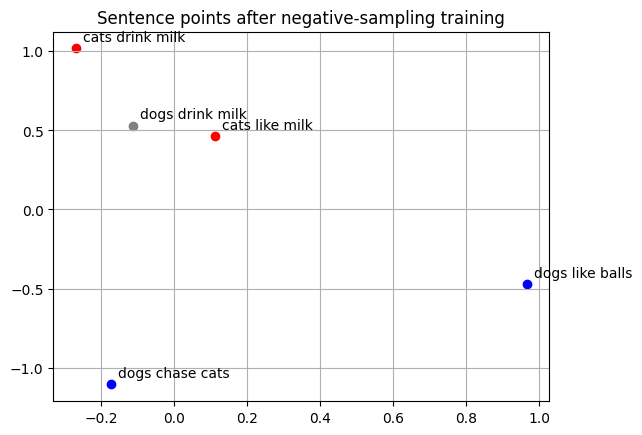

In [15]:
from matplotlib import pyplot as plt
import numpy as np

# the new sentence, like mystery_flower (every word must be in the vocabulary)
mystery_sentence = "dogs drink milk"

# PCA basis from the trained word embeddings: d = 3 -> 2D
centered = E - E.mean(axis=0)
_, _, Vt = np.linalg.svd(centered, full_matrices=False)
basis = Vt[:2].T                                   # (d, 2)

def sentence_point(sentence):
    ids = [word_to_id[w] for w in sentence.split()]
    vec = E[ids].mean(axis=0) - E.mean(axis=0)     # average word vector
    return vec @ basis                             # (2,)

# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(corpus)):
        c = 'r'
        if corpus[i].split()[0] == "dogs":           # cats sentence = r, dogs sentence = b
            c = 'b'
        x, y = sentence_point(corpus[i])
        plt.scatter([x], [y], c=c)
        plt.annotate(corpus[i], (x, y), textcoords="offset points", xytext=(5, 5))

    mx, my = sentence_point(mystery_sentence)
    plt.scatter([mx], [my], c='gray')
    plt.annotate(mystery_sentence, (mx, my), textcoords="offset points", xytext=(5, 5))

vis_data()
plt.title("Sentence points after negative-sampling training")
plt.show()

In [16]:
center = word_to_id["cats"]
p = sigmoid(E[center] @ W)

for i in np.argsort(p)[::-1]:
    print(f"{id_to_word[i]:>6}: sigma {p[i]:.3f}")

  like: sigma 0.826
 chase: sigma 0.588
 drink: sigma 0.567
  cats: sigma 0.024
  dogs: sigma 0.024
 balls: sigma 0.023
  milk: sigma 0.022


**Window based cooccurance matrix with new corpus - 17/10/2026**

In [17]:
import numpy as np

# 1. Corpus ("." is treated as a word, as in the slide)
corpus = ["I like deep learning .",
          "I like NLP .",
          "I enjoy flying ."]

sentences = [s.split() for s in corpus]

# 2. Vocabulary: written in the slide's column order
#    (sorted(set(...)) would give a different order, but the matrix would be the same)
vocab = ["I", "like", "enjoy", "deep", "learning", "NLP", "flying", "."]
word_to_id = {w: i for i, w in enumerate(vocab)}
id_to_word = {i: w for w, i in word_to_id.items()}
V = len(vocab)

window = 1

# 3. Co-occurrence matrix X
X = np.zeros((V, V), dtype=int)

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]
    for i, center in enumerate(ids):
        for j in range(max(0, i - window), min(len(ids), i + window + 1)):
            if i != j:
                X[center, ids[j]] += 1

print(vocab)
print(X)

# optional: print with labels
import pandas as pd
print(pd.DataFrame(X, index=vocab, columns=vocab))

['I', 'like', 'enjoy', 'deep', 'learning', 'NLP', 'flying', '.']
[[0 2 1 0 0 0 0 0]
 [2 0 0 1 0 1 0 0]
 [1 0 0 0 0 0 1 0]
 [0 1 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 1]
 [0 1 0 0 0 0 0 1]
 [0 0 1 0 0 0 0 1]
 [0 0 0 0 1 1 1 0]]
          I  like  enjoy  deep  learning  NLP  flying  .
I         0     2      1     0         0    0       0  0
like      2     0      0     1         0    1       0  0
enjoy     1     0      0     0         0    0       1  0
deep      0     1      0     0         1    0       0  0
learning  0     0      0     1         0    0       0  1
NLP       0     1      0     0         0    0       0  1
flying    0     0      1     0         0    0       0  1
.         0     0      0     0         1    1       1  0


**Word_vec 17102026**

In [18]:
import numpy as np

# 1. Corpus
corpus = [
    "cats like milk",
    "cats drink milk",
    "dogs like milk",
    "dogs chase balls",
    "cats chase balls"
]

# 2. Build vocabulary
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)
print("Vocabulary:", vocab)

# Hyperparameters
window = 1
d = 3
learning_rate = 0.05
epochs = 500

# 3. Generate center-context training pairs
pairs = []

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):
        for j in range(max(0, i - window),
                       min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Training pairs:", (pairs))

Vocabulary: ['balls', 'cats', 'chase', 'dogs', 'drink', 'like', 'milk']
Training pairs: [(1, 5), (5, 1), (5, 6), (6, 5), (1, 4), (4, 1), (4, 6), (6, 4), (3, 5), (5, 3), (5, 6), (6, 5), (3, 2), (2, 3), (2, 0), (0, 2), (1, 2), (2, 1), (2, 0), (0, 2)]



Learned word embeddings:
balls [-1.266 -1.971 -1.919]
cats [ 0.009 -1.334  0.439]
chase [ 1.113  0.284 -1.355]
dogs [-1.852 -1.044  0.163]
drink [0.983 1.665 1.2  ]
like [-0.486  1.588 -0.12 ]
milk [-0.314 -0.637  2.018]


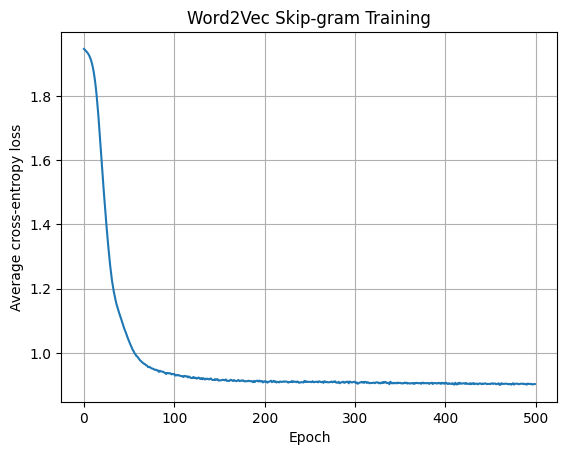

In [19]:
# 4. Initialize parameters randomly
np.random.seed(42)

E = np.random.randn(V, d) * 0.1
W = np.random.randn(d, V) * 0.1

# 5. Softmax function
def softmax(x):
    x = x - np.max(x)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

# 6. Train Skip-gram
losses = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0

    for center, context in pairs:

        # Forward pass
        h = E[center].copy()
        scores = h @ W
        probabilities = softmax(scores)

        # Cross-entropy loss
        loss = -np.log(probabilities[context] + 1e-12)
        total_loss += loss

        # Backpropagation
        error = probabilities.copy()
        error[context] -= 1

        gradient_W = np.outer(h, error)
        gradient_h = W @ error

        # Update parameters
        W -= learning_rate * gradient_W
        E[center] -= learning_rate * gradient_h

    losses.append(total_loss / len(pairs))

# 7. Print learned embeddings
print("\nLearned word embeddings:")
for word, idx in word_to_id.items():
    print(word, np.round(E[idx], 3))

# 8. Plot training loss
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("Word2Vec Skip-gram Training")
plt.grid(True)
plt.show()

In [20]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b) + 1e-12
    )

def similar_words(word, top_k=3):
    idx = word_to_id[word]
    scores = []

    for j in range(V):
        if j != idx:
            sim = cosine_similarity(E[idx], E[j])
            scores.append((id_to_word[j], sim))

    return sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]

print("Words similar to cats:", similar_words("cats"))
print("Words similar to dogs:", similar_words("dogs"))

Words similar to cats: [('milk', np.float64(0.5770610126869122)), ('dogs', np.float64(0.4834203312965598)), ('balls', np.float64(0.4174956092620975))]
Words similar to dogs: [('balls', np.float64(0.6335467734426936)), ('cats', np.float64(0.4834203312965598)), ('milk', np.float64(0.34532935556619815))]
